# Rain Prediction with Logistic Regression

Data Science, Semester 3, Plaksha University (Assignment 3A).

Predicts whether it will rain from five weather measurements (temperature, humidity, wind speed, cloud cover, pressure) using logistic regression. The dataset has 2,500 days, of which only 12.6% are rainy, so the evaluation also looks at how the model handles the rarer class.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score, confusion_matrix, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

plt.rcParams["figure.dpi"] = 100
data = pd.read_csv("data/weather_forecast_data.csv")
features = ["Temperature", "Humidity", "Wind_Speed", "Cloud_Cover", "Pressure"]
data["Rain"] = data["Rain"].map({"rain": 1, "no rain": 0})
print(data.shape)
data.describe().round(2)

(2500, 6)


,Temperature,Humidity,Wind_Speed,Cloud_Cover,Pressure,Rain
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,22.58,64.35,9.91,49.66,1014.31,0.13
std,7.33,19.95,5.78,29.12,20.20,0.33
min,10.00,30.01,0.01,0.02,980.01,0.00
25%,16.36,47.34,4.76,23.90,996.94,0.00
50%,22.54,63.92,9.91,49.49,1013.43,0.00
75%,28.98,81.56,14.95,75.32,1031.74,0.00
max,35.00,100.00,20.00,100.00,1049.99,1.00


## Exploratory analysis

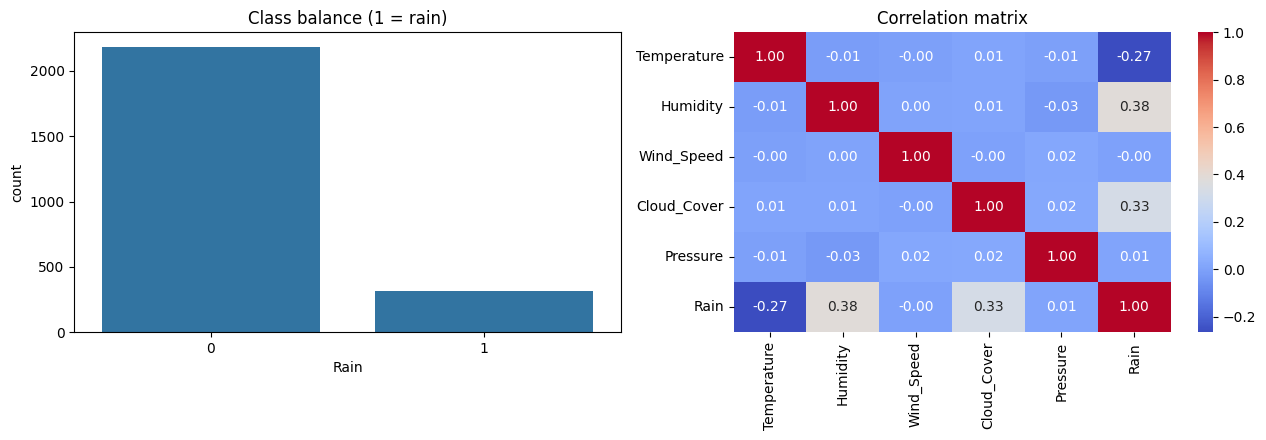

,correlation with Rain
Humidity,0.382
Cloud_Cover,0.326
Pressure,0.008
Wind_Speed,-0.001
Temperature,-0.266


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x="Rain", data=data, ax=axes[0])
axes[0].set_title("Class balance (1 = rain)")
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("images/eda.png")
plt.show()
data.corr()["Rain"].drop("Rain").sort_values(ascending=False).round(3).to_frame("correlation with Rain")

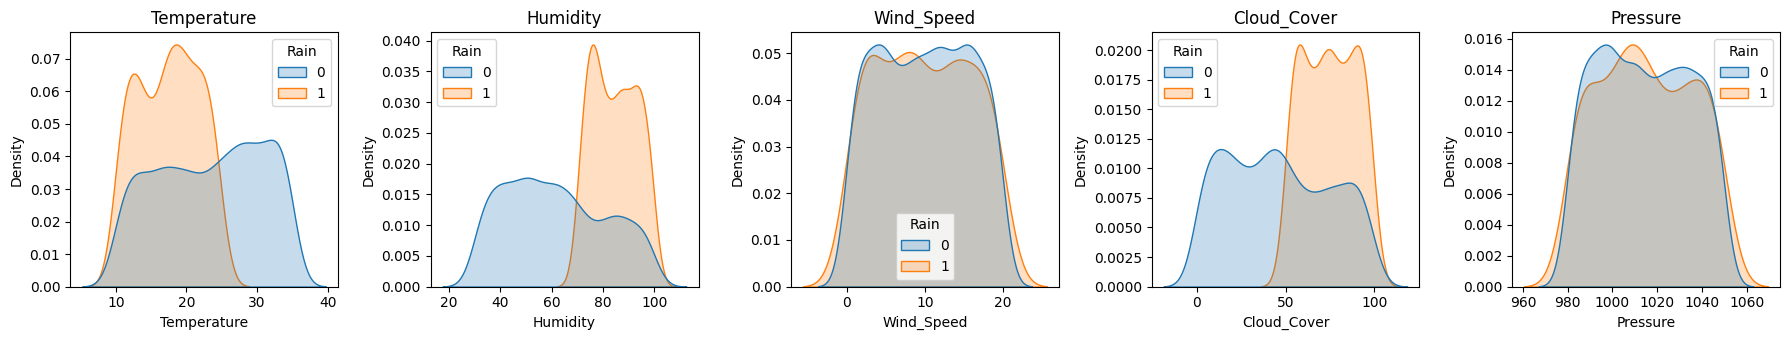

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, f in zip(axes, features):
    sns.kdeplot(data=data, x=f, hue="Rain", common_norm=False, fill=True, ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.savefig("images/feature_distributions.png")
plt.show()

Humidity and cloud cover separate rainy from dry days most clearly, and temperature is lower on rainy days. Wind speed and pressure barely differ between the two classes.

## Train, validation and test split

The data is split 70 / 15 / 15 **before** scaling, so the scaler only learns from the training data (no information leaks from the test set).

In [4]:
X, y = data[features], data["Rain"]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(d) for d in (X_train, X_val, X_test))
print("train", X_train.shape, "validation", X_val.shape, "test", X_test.shape)

train (1750, 5) validation (375, 5) test (375, 5)


## Models

1. Plain logistic regression (as in the original assignment).
2. Logistic regression with `class_weight="balanced"`. This weights the rare rainy days more, trading some precision for higher recall.

In [5]:
models = {"Logistic regression": LogisticRegression(),
          "Logistic regression (balanced)": LogisticRegression(class_weight="balanced")}
rows = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    for split, Xs, ys in [("validation", X_val_s, y_val), ("test", X_test_s, y_test)]:
        p = m.predict(Xs)
        prob = m.predict_proba(Xs)[:, 1]
        rows.append({"model": name, "split": split, "accuracy": accuracy_score(ys, p), "precision": precision_score(ys, p),
                     "recall": recall_score(ys, p), "F1": f1_score(ys, p), "AUC-ROC": roc_auc_score(ys, prob)})
results = pd.DataFrame(rows).round(3)
results

,model,split,accuracy,precision,recall,F1,AUC-ROC
0,Logistic regression,validation,0.909,0.638,0.638,0.638,0.951
1,Logistic regression,test,0.928,0.763,0.617,0.682,0.971
2,Logistic regression (balanced),validation,0.861,0.473,0.936,0.629,0.951
3,Logistic regression (balanced),test,0.915,0.603,0.936,0.733,0.972


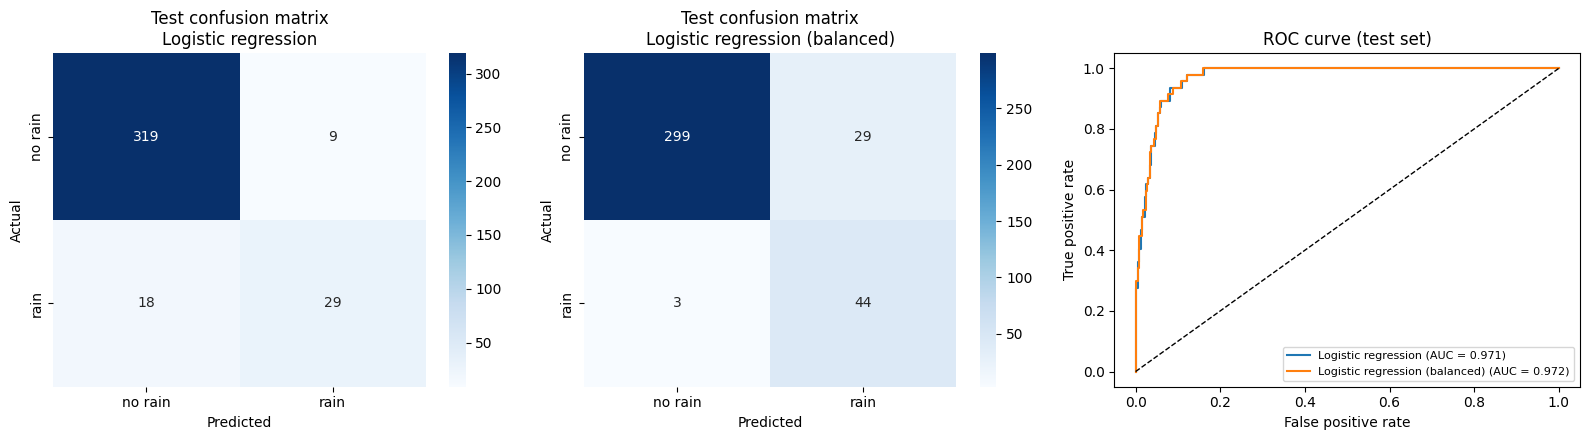

              precision    recall  f1-score   support

     no rain       0.95      0.97      0.96       328
        rain       0.76      0.62      0.68        47

    accuracy                           0.93       375
   macro avg       0.85      0.79      0.82       375
weighted avg       0.92      0.93      0.92       375



In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes[:2], models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=["no rain", "rain"], yticklabels=["no rain", "rain"])
    ax.set_title(f"Test confusion matrix\n{name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test_s)[:, 1])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, m.predict_proba(X_test_s)[:, 1]):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curve (test set)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig("images/evaluation.png")
plt.show()

print(classification_report(y_test, models["Logistic regression"].predict(X_test_s), target_names=["no rain", "rain"]))

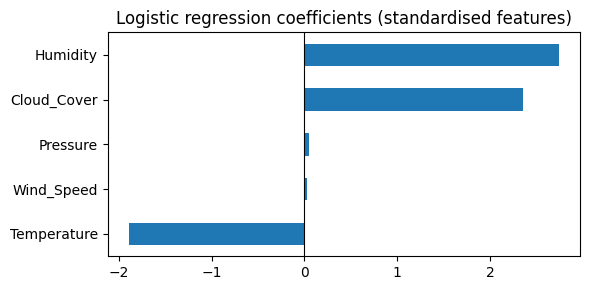

,coefficient
Temperature,-1.886
Wind_Speed,0.031
Pressure,0.056
Cloud_Cover,2.354
Humidity,2.739


In [7]:
coef = pd.Series(models["Logistic regression"].coef_[0], index=features).sort_values()
coef.plot.barh(figsize=(6, 3), title="Logistic regression coefficients (standardised features)")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.savefig("images/coefficients.png")
plt.show()
coef.round(3).to_frame("coefficient")

## Conclusions

- Humidity and cloud cover are the strongest predictors of rain, and higher temperature makes rain less likely. Wind speed and pressure add almost nothing.
- Plain logistic regression reaches **92.8% test accuracy** with a **test AUC of 0.97** (0.95 on validation). Because rain is rare, accuracy flatters the model: it still misses about 4 in 10 rainy days (recall 0.62).
- Class weighting raises recall on rainy days to over 90%, at the cost of more false alarms. Which model to use depends on whether missing rain or a false alarm costs more.